In [1]:
import cv2 as cv
import os
import tensorflow as tf
import matplotlib.pyplot as plt  # Corrected from pylot to pyplot

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

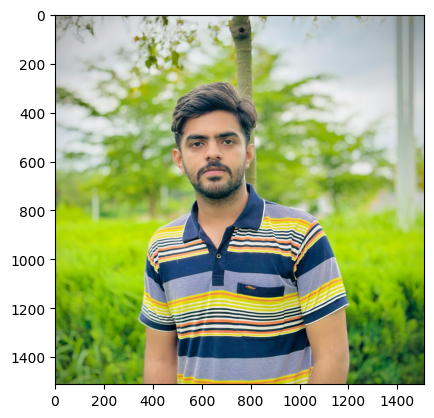

In [2]:
img = cv.imread("I:/Project_ANN/images/zain/1.jpg")

img = cv.cvtColor(img, cv.COLOR_BGR2RGB)


plt.imshow(img)

In [3]:
from mtcnn.mtcnn import MTCNN

detector =MTCNN()
results = detector.detect_faces(img)

In [4]:
results

[{'box': [529, 411, 251, 320],
  'confidence': 1.0,
  'keypoints': {'nose': [641, 576],
   'mouth_right': [698, 645],
   'right_eye': [701, 518],
   'left_eye': [581, 528],
   'mouth_left': [605, 651]}}]

In [5]:
x,y,w,h = results[0]['box']


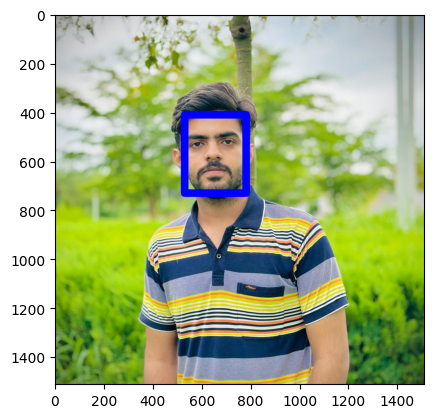

In [6]:
img = cv.rectangle( img, (x,y), (x+w,y+h), (0,0,255),30)
plt.imshow(img)

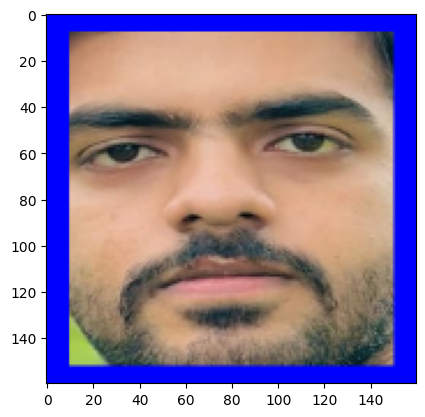

In [7]:
my_face = img[y:y+h, x:x+w]
my_face =cv.resize(my_face, (160,160))
plt.imshow(my_face)

In [8]:
my_face

array([[[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       ...,

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]],

       [[  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255],
        ...,
        [  0,   0, 255],
        [  0,   0, 255],
        [  0,   0, 255]]

In [9]:
class FACELOADING:
    def __init__(self, directory):
           self.directory = directory
           self.target_size = (160,160)
           self.X = []
           self.Y = []
           self.detector = MTCNN()


    def extract_face(self, filename) :   
        img = cv.imread(filename)
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
        x,y,w,h =self.detector.detect_faces(img)[0]['box']
        x,y = abs(x), abs(y)
        face = img[y:y+h, x: x+w]
        face_arr= cv.resize(face, self.target_size)
        return face_arr
    

    def load_faces(self, dir):
        FACES = []
        for im_name in os.listdir(dir):
            try:
                path = dir + im_name
                single_face = self.extract_face(path)
                FACES.append(single_face)
            except Exception as e:
                pass  # Silently ignore errors
        return FACES
    
    def load_classes(self):
        for sub_dir in os.listdir(self.directory):
            path = self.directory + '/' + sub_dir+'/'
            FACES = self.load_faces(path)
            labels = [sub_dir for _ in range(len(FACES))]
            print(f"load successfully: {len(labels)}")
            self.X.extend(FACES)
            self.Y.extend(labels)
        return np.asarray(self.X), np.asarray(self.Y)
        
    
    def plot_images(self):
        ncols = 3  # Fixed number of columns
        nrows = (len(self.Y) + ncols - 1) // ncols  # Calculate rows needed dynamically

        plt.figure(figsize=(10, 10))  # Optional: Adjust figure size
        for num, image in enumerate(self.X):
            plt.subplot(nrows, ncols, num + 1)  # Ensure num is within valid range
            plt.imshow(image)
            plt.axis('off')

In [10]:
import numpy as np


In [11]:
faceloading = FACELOADING(r"I:\Project_ANN\images")
X,Y = faceloading.load_classes()

load successfully: 5
load successfully: 5
load successfully: 2
load successfully: 2
load successfully: 3
load successfully: 2
load successfully: 4
load successfully: 3
load successfully: 3
load successfully: 2
load successfully: 2
load successfully: 8


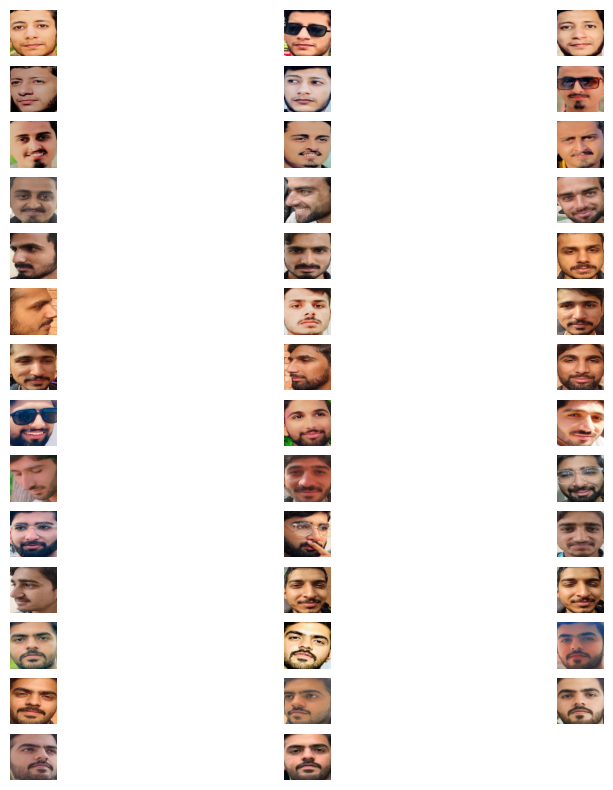

In [12]:
faceloading.plot_images()

In [ ]:
!pip install keras-facenet

FACE-NET

In [13]:
from keras_facenet import FaceNet 
embedder = FaceNet()

def get_embedding(face_img):
    face_img = face_img.astype('float32')
    face_img = np.expand_dims(face_img, axis=0)
    #4D (Nonex160x160x3)
    yhat = embedder.embeddings(face_img)
    return yhat[0]


In [14]:
EMBEDDED_X =[]

for img in X:
    EMBEDDED_X.append(get_embedding(img))

EMBEDDED_X = np.asarray(EMBEDDED_X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 12s 12s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 464ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 442ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 456ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 525ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 552ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 566ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 426ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 393ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 398ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 496ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 422ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 499ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 429ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

In [15]:
np.savez_compressed('faces_embeddings_done_4classes.npz',EMBEDDED_X,Y)

In [16]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()
encoder.fit(Y)
Y = encoder.transform(Y)

In [17]:
Y

array([ 0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  3,  3,  4,  4,  2,  2,  2,
        5,  5,  6,  6,  6,  6,  7,  7,  7,  8,  8,  8,  9,  9, 10, 10, 11,
       11, 11, 11, 11, 11, 11, 11])

In [ ]:
import numpy as np
import pickle
import cv2
from keras_facenet import FaceNet 

# Initialize FaceNet model
embedder = FaceNet()

def get_embedding(face_img):
    face_img = face_img.astype('float32')

    # Ensure the image has 3 channels (convert grayscale to RGB if needed)
    if face_img.shape[-1] != 3:
        face_img = cv2.cvtColor(face_img, cv2.COLOR_GRAY2RGB)

    # Resize image to 160x160 to match FaceNet input
    face_img = cv2.resize(face_img, (160, 160))

    # Convert to 4D tensor (1, 160, 160, 3)
    face_img = np.expand_dims(face_img, axis=0)  

    # Generate embedding
    yhat = embedder.embeddings(face_img)
    return yhat[0]  

# Assuming X contains face images
EMBEDDED_X = [get_embedding(img) for img in X]
EMBEDDED_X = np.asarray(EMBEDDED_X)

# Save embeddings and labels
data = {"embeddings": EMBEDDED_X, "labels": Y}

with open("facenet_embeddings.pkl", "wb") as f:
    pickle.dump(data, f)

print("✅ FaceNet embeddings saved successfully!")


1/1 ━━━━━━━━━━━━━━━━━━━━ 15s 15s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 635ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 453ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 592ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 612ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 556ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 716ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 614ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 468ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step


: 

: 

In [2]:
import numpy as np
import pickle

# Load precomputed FaceNet embeddings (assumed saved earlier)
with open("facenet_embeddings.pkl", "rb") as f:
    data = pickle.load(f)

X = np.array(data["embeddings"])  # FaceNet embeddings
Y = np.array(data["labels"])      # Corresponding labels


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [3]:
from sklearn.preprocessing import LabelEncoder

# Convert string labels to integers
label_encoder = LabelEncoder()
Y = label_encoder.fit_transform(Y)  # Convert labels

# Split the dataset
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


In [4]:
import numpy as np
import pickle
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# Load embeddings and labels
faces_embeddings = np.load("faces_embeddings_done_4classes.npz")
X = faces_embeddings['arr_0']  # Face embeddings (features)
Y = faces_embeddings['arr_1']  # Labels (names)

# Encode labels before splitting
encoder = LabelEncoder()
Y_encoded = encoder.fit_transform(Y)

# Split dataset
X_train, X_test, Y_train, Y_test = train_test_split(X, Y_encoded, test_size=0.2, random_state=42)

# Define CNN model
cnn_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dense(len(np.unique(Y_encoded)), activation='softmax')  # Output layer for classification
])

# Compile CNN model
cnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train CNN model
cnn_model.fit(X_train, Y_train, epochs=50, batch_size=8, validation_data=(X_test, Y_test))

# Evaluate CNN model
loss, accuracy = cnn_model.evaluate(X_test, Y_test)
print(f"Test Accuracy: {accuracy:.2f}")

# Save CNN model
cnn_model.save("face_recognition_cnn.h5")

# Save the label encoder
with open("encoder.pkl", 'wb') as file:
    pickle.dump(encoder, file)

# Predict using CNN model
cnn_preds_train = np.argmax(cnn_model.predict(X_train), axis=1)
cnn_preds_test = np.argmax(cnn_model.predict(X_test), axis=1)

# Evaluate accuracy of CNN model
print("Train Accuracy:", accuracy_score(Y_train, cnn_preds_train))
print("Test Accuracy:", accuracy_score(Y_test, cnn_preds_test))


c:\Program Files\Python312\Lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 214ms/step - accuracy: 0.0667 - loss: 2.4934 - val_accuracy: 0.4444 - val_loss: 2.4352
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.4417 - loss: 2.4239 - val_accuracy: 0.5556 - val_loss: 2.3922
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.6292 - loss: 2.3556 - val_accuracy: 0.5556 - val_loss: 2.3470
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.4292 - loss: 2.3353 - val_accuracy: 0.5556 - val_loss: 2.2955
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.6167 - loss: 2.2149 - val_accuracy: 0.5556 - val_loss: 2.2361
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.6833 - loss: 2.1528 - val_accuracy: 0.5556 - val_loss: 2.1679
Epoch 7/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 241ms/step - accuracy: 0.4875 - loss: 2.0935 - val_accuracy: 0.5556 - val_loss: 2.0883
Epoch 8/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.7042 - loss: 1.9470 - val_accuracy: 0.5556 - val_loss: 1.9

Test Accuracy: 1.00
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 312ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 288ms/step
Train Accuracy: 1.0
Test Accuracy: 1.0


In [ ]:
import pickle
from sklearn.svm import SVC

# Example: train a simple SVM model
model = SVC()
# Assuming you have your data in X_train and y_train
# model.fit(X_train, y_train)

# Save the model
with open('160x160.pkl', 'wb') as file:
    pickle.dump(model, file)


TEST IMAGE

In [ ]:
t_im = cv.imread("testimg.jpg")
t_im = cv.cvtColor(t_im, cv.COLOR_BGR2RGB)
x,y,w,h = detector.detect_faces(t_im)[0]['box']

In [ ]:
t_im = t_im[y:y+h, x:x+w]
t_im = cv.resize(t_im,(160,160))
test_im = get_embedding(t_im)

In [ ]:
test_im =[test_im]
ypreds = model.predict(test_im)

In [ ]:
ypreds

In [ ]:
encoder.inverse_transform(ypreds)